# Dedispersing CHIME/FRB baseband data for FRBayes

This notebook turns one CHIME/FRB beamformed baseband file into the `.npz` file FRBayes reads. It
needs the CHIME/FRB `baseband_analysis` package. The file it writes holds:

| key                     | contents                                                             |
|-------------------------|----------------------------------------------------------------------|
| `power`                 | the dedispersed dynamic spectrum, (n_chan, n_time), good channels only |
| `freq`                  | channel centre frequencies (MHz)                                     |
| `time`                  | sample times (s)                                                     |
| `dm_dedispersion`       | the DM the data were dedispersed with (pc cm⁻³)                      |
| `dedispersion_ref_freq` | the frequency the dedispersion aligned the channels to (MHz)         |

`frbayes.data.prepare_burst` reads the last two automatically, and `frbayes.results.save_run` records
them with the fit. The file is written to `examples/data/`, next to the `notebooks/` folder this
notebook is in, where the tutorial reads the example bursts.

## Settings

In [1]:
import os
import tempfile
from pathlib import Path

import numpy as np
from baseband_analysis.dev.Morphology_dev import singlebeam_to_input
%matplotlib inline

event_id = "23438043"                     # CHIME/FRB event number
in_file = "/arc/projects/chime_frb/BaseCat2/beamformed_files/FRB20181221A_23438043_beamformed.h5"
out_file = Path("..") / "data" / f"event_{event_id}_BB.npz"   # examples/data, next to examples/notebooks

# The frequency (MHz) the dedispersion aligns the channels to, at which the time axis keeps the
# telescope's clock: singlebeam_to_input calls baseband_analysis.core.dedispersion.coherent_dedisp
# without f_ref, whose default is 400 MHz
DEDISPERSION_REF_FREQ = 400.0

## Load and dedisperse, coherently

On its way through the ionized gas between galaxies, a burst's lower frequencies are delayed more than
its higher ones (dispersion), in proportion to the DM. *Incoherent* dedispersion shifts each channel's
power by the delay at the channel's centre, which leaves the sweep across each channel's own width as
smearing. *Coherent* dedispersion instead works on the recorded voltages, before they are squared into
power: within each channel it undoes the delay at every frequency, by multiplying the voltages' Fourier
transform by the inverse of the gas's effect, so no smearing is left. Only baseband data, which keep
the voltages, allow it.

`singlebeam_to_input` loads the beamformed data, finds a time downsampling at which the burst reaches
`snr_cutoff`, and fits the structure-maximizing DM (`fit_DM=True`). The beamformed files come already
coherently dedispersed at the DM in their `DM_coherent` attribute; without `co_dedisp=True` the
function would only shift the channels incoherently from there to the fitted DM. With
`co_dedisp=True` it dedisperses the voltages coherently again, at the fitted DM, with
`baseband_analysis.core.dedispersion.coherent_dedisp`, which also aligns the channels to 400 MHz, and
forms the power from them. The dedispersion is then entirely coherent, so FRBayes is set up with
`DM_incoherent = 0`; the check after the call confirms it.

With `diagnostic_plots=True`, `singlebeam_to_input` also saves its plots as `.png` and `.pdf` files
in the folder it runs in. It is run in a temporary folder, deleted afterwards, so the plots are shown
here but no files are left behind.

Loading /arc/projects/chime_frb/BaseCat2/beamformed_files/FRB20181221A_23438043_beamformed.h5
Checking if baseband data was already de-smeared..
No DM in tiedbeam_baseband, so continuing on
---------Downsampling---------
Finding the best downsample. The SNr cutoff used is:  12


/opt/pysetup/baseband_analysis/core/signal.py:106: RuntimeWarning: Mean of empty slice
  if not np.isnan(np.nanmean(power_in[-1], axis=0)).any():
/opt/pysetup/baseband_analysis/core/flagging.py:103: RuntimeWarning: Mean of empty slice
  spect = get_spect(np.nanmean(power_beam, axis=-1), thres=thres_mean)
/opt/pysetup/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
[2026-11-24 05:59:41,327] WARNING Pulse not in the valid range, noise will be added to search the full dump.
/opt/pysetup/baseband_analysis/core/signal.py:176: RuntimeWarning: Mean of empty slice
  return np.nanmean(power, axis=0) * np.sqrt(


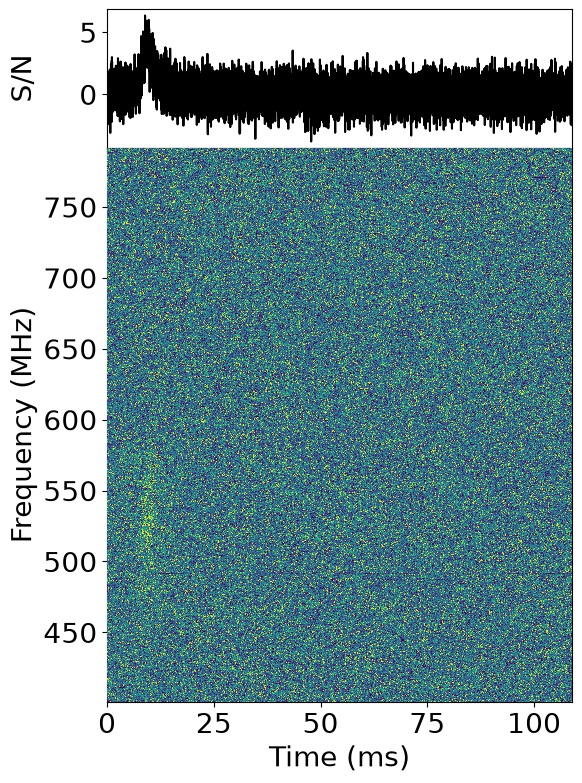

Profile already came in downsampled to:  4
SNR for initial downsampling factor 4: 6.352558392900571
The input dowsample was not bright enough. Finding the best downsample .....


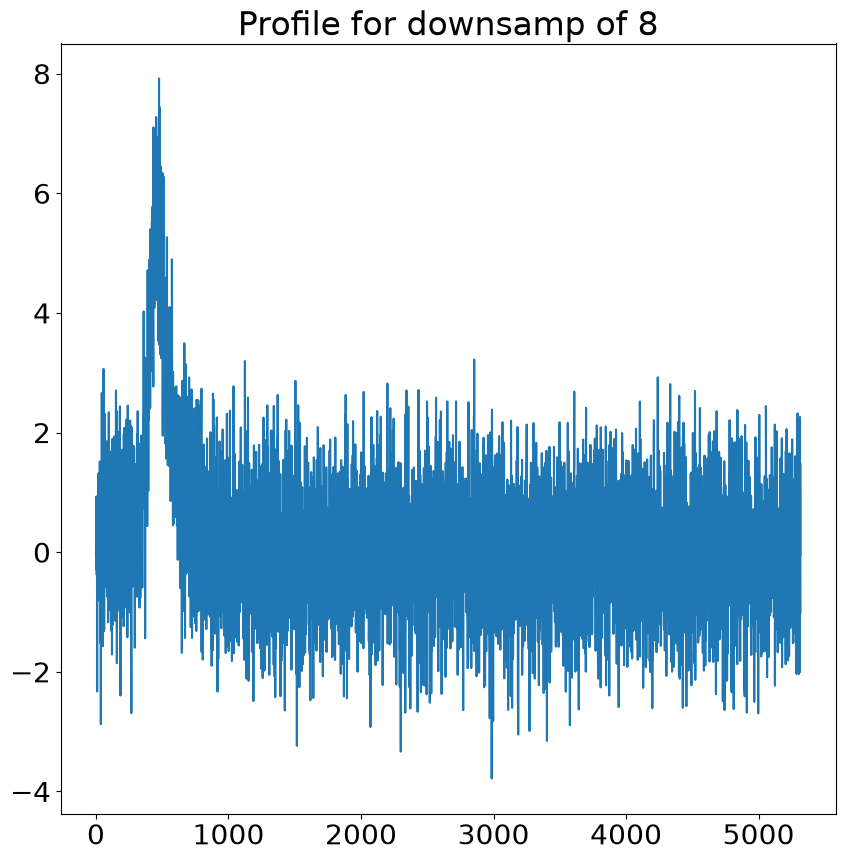

SNR for downsampling factor 8: 7.918472255058142


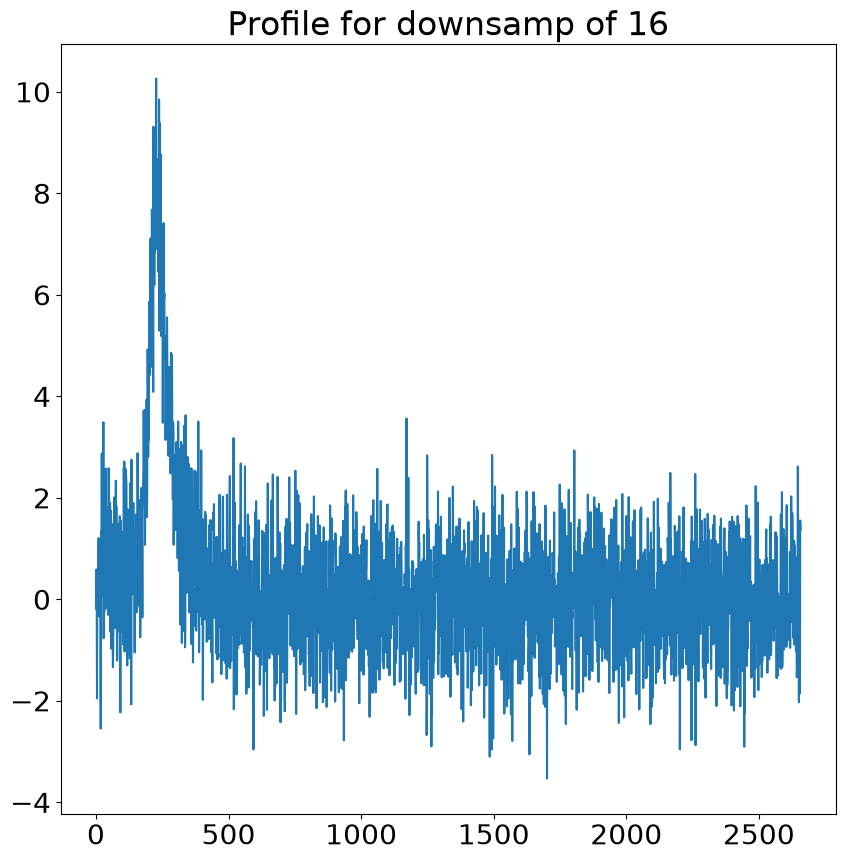

SNR for downsampling factor 16: 10.261608740906325


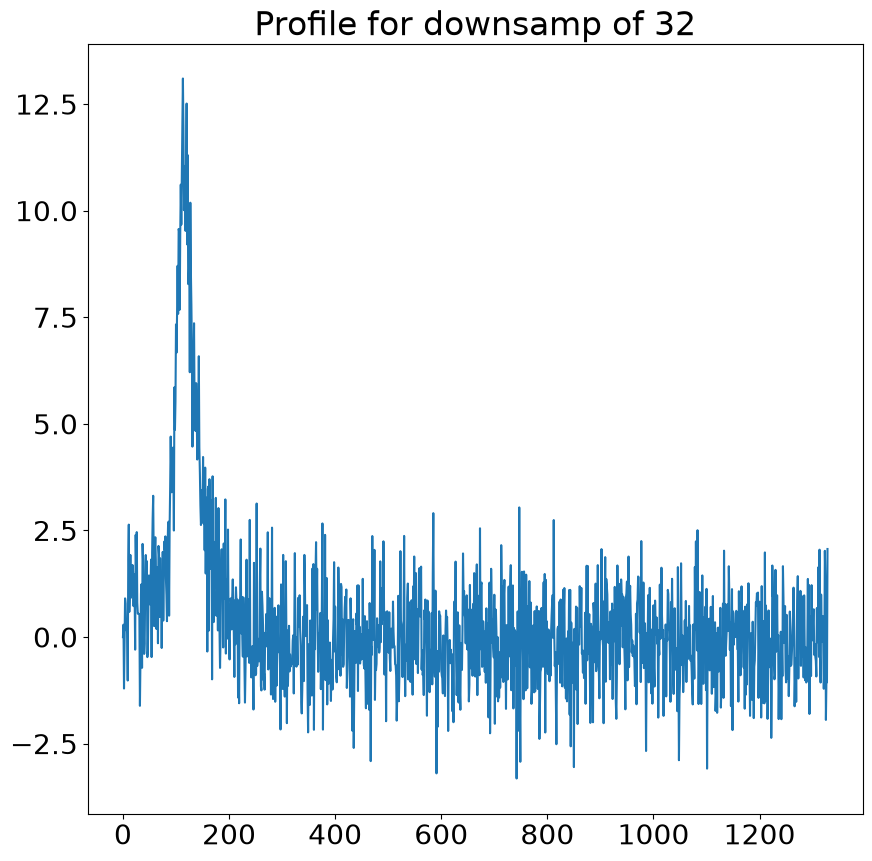

SNR for downsampling factor 32: 13.099028214724356
The final downsample is 32
We will use 32 as downsampling factor from now on
New downsampling factor != original factor. Going to re-run get_snr as a result to get a new power array


[2026-11-24 06:00:01,388] WARNING Pulse not in the valid range, noise will be added to search the full dump.


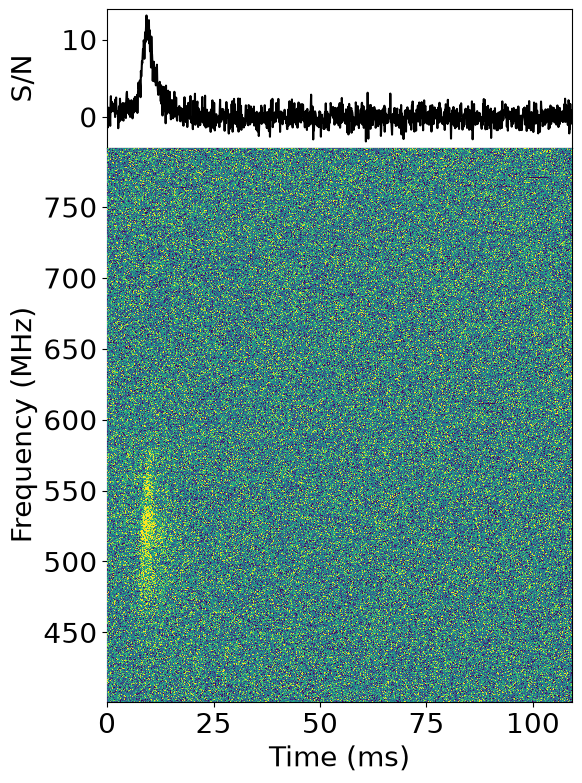

---------DM DETERMINATION---------
Running get_snr() to get an estimate on S/N maximizing DM


[2026-11-24 06:00:14,673] INFO Best DM found at 316.19601179767204 pc/cc
[2026-11-24 06:00:19,014] WARNING Pulse not in the valid range, noise will be added to search the full dump.
[2026-11-24 06:00:30,348] INFO Best DM found at 316.1960205972281 pc/cc


The S/N maximizing DM is 316.1960205972281 pc/cc
Grabbing the burst profile
Getting the signal
Running structure maximizing DM script
The structure maximizing DM is 316.32666120973676 pc/cc +/- 0.07237685363026441 pc/cc
Coherently dedispersing the data at the given DM of 316.32666120973676 pc/cc
316.32666120973676 316.32666120973676 0
0.0 316.32666120973676 316.32666120973676


/opt/pysetup/baseband_analysis/core/signal.py:931: RuntimeWarning: Mean of empty slice
  power = np.nanmean(power, -1)


Running get_snr() again now at the final DM of:  316.32666120973676


[2026-11-24 06:01:29,470] WARNING Pulse not in the valid range, noise will be added to search the full dump.


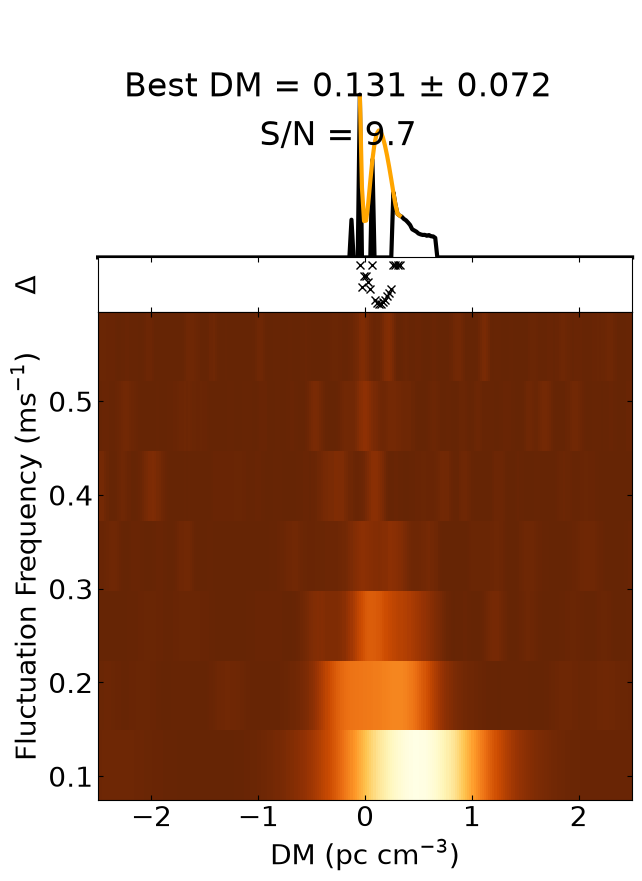

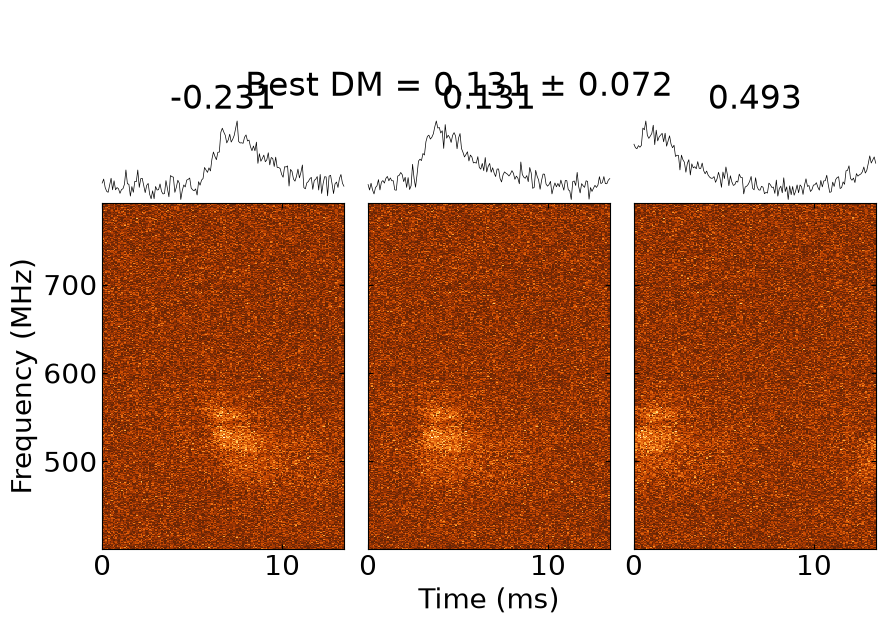

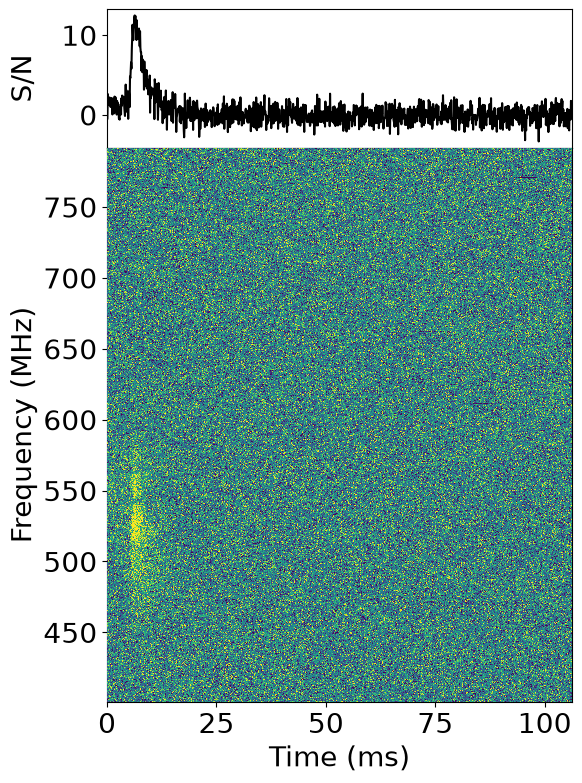

Getting the signal
Plotting a waterfall of the power


<Figure size 1000x1000 with 0 Axes>

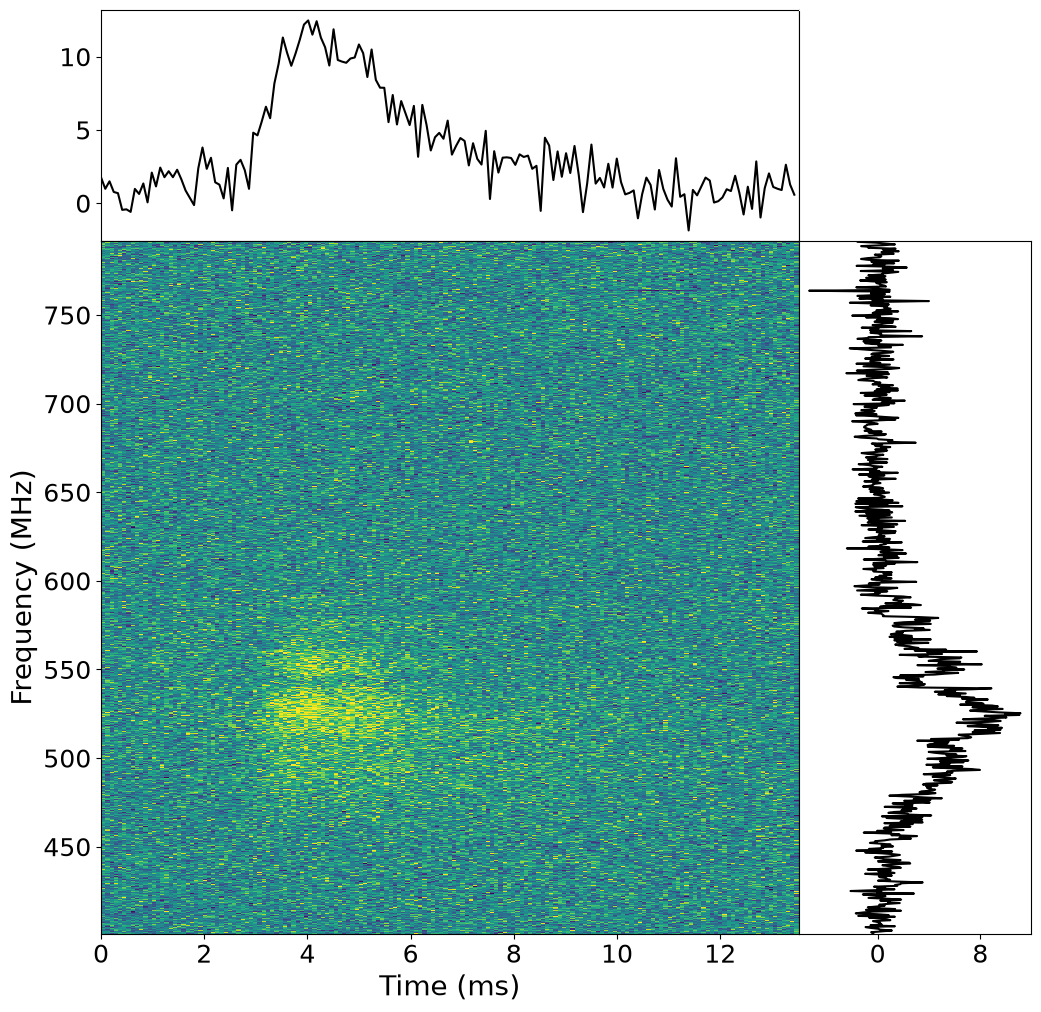

fitted DM 316.3267, coherently dedispersed at 316.3267 pc cm^-3: DM_incoherent = +0.0000


In [2]:
print(f"Loading {in_file}")
here = os.getcwd()
with tempfile.TemporaryDirectory() as scratch:      # the diagnostic plot files land here and are deleted
    os.chdir(scratch)
    try:
        (data, freq_id, freq, power, valid_channels, DM, DM_err, downsampling_factor, profile, t_res,
         start, full_power) = singlebeam_to_input(
            in_file,
            downsample=4,                 # starting downsampling in time; raised until the burst reaches snr_cutoff
            fit_DM=True,                  # fit the structure-maximizing DM
            co_dedisp=True,               # then dedisperse the voltages coherently at that DM
            diagnostic_plots=True,
            snr_cutoff=12,
        )
    finally:
        os.chdir(here)

# The DM the power was coherently dedispersed at should now be the fitted DM; any difference was
# removed only incoherently, and is the DM_incoherent FRBayes would need
DM_coherent = float(data["tiedbeam_power"].attrs["DM_coherent"])
print(f"fitted DM {float(DM):.4f}, coherently dedispersed at {DM_coherent:.4f} pc cm^-3: "
      f"DM_incoherent = {float(DM) - DM_coherent:+.4f}")

## Build the arrays and check them

FRBayes needs the bad channels removed, not zeroed or masked, and times in seconds. The checks below
drop any channel that is entirely zero or holds a NaN, and print the time resolution and segment
length so the units can be checked by eye.

In [3]:
power = np.asarray(power, dtype=float)
freq = np.asarray(freq, dtype=float)
n_time = power.shape[1]
time = start + t_res * np.arange(n_time)                   # seconds

bad = ~np.isfinite(power).all(axis=1) | np.all(power == 0, axis=1)
if bad.any():
    print(f"dropping {bad.sum()} channels that are all zero or hold a NaN")
    power, freq = power[~bad], freq[~bad]

df = np.diff(np.sort(freq))
print(f"{power.shape[0]} channels, {freq.min():.1f}-{freq.max():.1f} MHz, "
      f"{np.sum(df > 1.5 * np.median(df))} gaps where bad channels were removed")
print(f"{n_time} samples of {t_res * 1e6:.2f} us (downsampling {downsampling_factor}), "
      f"segment {n_time * t_res * 1e3:.2f} ms")
print(f"dedispersed with DM {float(DM):.4f} +/- {float(DM_err):.4f} pc cm^-3")

807 channels, 400.8-791.8 MHz, 104 gaps where bad channels were removed
165 samples of 81.92 us (downsampling 32), segment 13.52 ms
dedispersed with DM 316.3267 +/- 0.0000 pc cm^-3


## Save

In [4]:
out_file.parent.mkdir(parents=True, exist_ok=True)
arrays = dict(power=power, freq=freq, time=time,
              dm_dedispersion=float(DM), dedispersion_ref_freq=float(DEDISPERSION_REF_FREQ))
np.savez_compressed(out_file, **arrays)
print(f"saved {out_file}: {', '.join(arrays)}")

saved ../data/event_23438043_BB.npz: power, freq, time, dm_dedispersion, dedispersion_ref_freq
